# **Regression Problem**

In [155]:
from sklearn.datasets import make_regression
import numpy as np
import matplotlib.pyplot as plt

# Generate dataset with 2 features
X, y = make_regression(n_samples=100, n_features=2, noise=10, random_state=42)

# Reshape y to be a column vector
y = y.reshape(-1, 1)
print(X[:5])
# Normalize inputs (optional for stability)
X = (X - X.mean(axis=0)) / X.std(axis=0)
y = (y - y.mean()) / y.std()

print(X.shape, y.shape)  # Should print (100, 2) (100, 1)

[[-1.1913035   0.65655361]
 [ 0.05820872 -1.1429703 ]
 [ 0.58685709  2.19045563]
 [ 0.47323762 -0.07282891]
 [ 0.73846658  0.17136828]]
(100, 2) (100, 1)


In [156]:
y[:10]

array([[-0.3964218 ],
       [-0.73472619],
       [ 2.05849782],
       [ 0.34301687],
       [ 0.86277667],
       [-1.18172327],
       [-1.60388545],
       [ 0.32548548],
       [ 1.88856621],
       [ 1.53213785]])

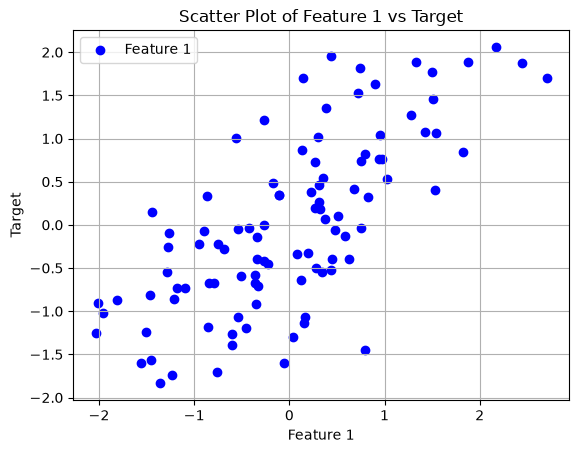

In [157]:
## plotting data (scatter plot)
plt.scatter(X[:, 1], y, color='blue', label='Feature 1')
plt.xlabel("Feature 1")
plt.ylabel("Target")
plt.title("Scatter Plot of Feature 1 vs Target")
plt.legend()
plt.grid()
plt.show()

In [160]:
w_12 = np.random.randn()
print(w_12)  # Should print a random number

-0.4694743859349521


In [161]:
# w_11 = 1,5

w_11 = np.random.randn()
w_12 = np.random.randn()
w_13 = np.random.randn()
w_14 = np.random.randn()
w_21 = np.random.randn()
w_22 = np.random.randn()
b_11 = 0
b_12 = 0
b_2 = 0

# w_11 = w_12 = w_13 = w_14 = w_21 = w_22 = np.random.randn()*0.1
# b_11 = b_12 = b_2 = 0.0

In [162]:
w_21

-1.913280244657798

In [163]:
### Feed forward example
loss = 0
lr = 0.001

dL_dw21 = dL_dw22 = 0.0
dL_dw11 = dL_dw12 = dL_dw13 = dL_dw14 = 0.0
dL_db11 = dL_db12 = dL_db2 = 0.0
m = len(X)

for i in range(m):
    x1 = X[i, 0]
    x2 = X[i, 1]
    
    # Hidden layer
    a1 = w_11 * x1 + w_13 * x2 + b_11
    a2 = w_12 * x1 + w_14 * x2 + b_12
    
    # Output layer
    y_pred = a1 * w_21 + a2 * w_22 + b_2
    
    # Compute loss
    loss = loss + (y_pred - y[i, 0]) ** 2
    
    # Backpropagation
    dL_dy = 2 * (y_pred - y[i, 0])
    dL_dw21 += dL_dy * a1
    dL_dw22 += dL_dy * a2
    dL_db2 += dL_dy
    dL_da1 = dL_dy * w_21
    dL_da2 = dL_dy * w_22
    dL_dw11 += dL_da1 * x1
    dL_dw13 += dL_da1 * x2
    dL_db11 += dL_da1
    dL_dw12 += dL_da2 * x1
    dL_dw14 += dL_da2 * x2
    dL_db12 += dL_da2

dL_dw21 /= m; dL_dw22 /= m
dL_dw11 /= m; dL_dw13 /= m; dL_dw12 /= m; dL_dw14 /= m
dL_db2 /= m; dL_db11 /= m; dL_db12 /= m

# Update weights
w_21 = w_21 - lr * dL_dw21
w_22 -= lr * dL_dw22
b_2 -= lr * dL_db2
w_11 -= lr * dL_dw11
w_13 -= lr * dL_dw13
b_11 -= lr * dL_db11
w_12 -= lr * dL_dw12
w_14 -= lr * dL_dw14
b_12 -= lr * dL_db12

loss /= len(X)
print("Loss:", loss)

Loss: 0.935639099800093


In [164]:
### Feed forward example
lr = 0.01
m = len(X)
loss_history = []
epochs = 300
for epoch in range(epochs):
    dL_dw21 = dL_dw22 = 0.0
    dL_dw11 = dL_dw12 = dL_dw13 = dL_dw14 = 0.0
    dL_db11 = dL_db12 = dL_db2 = 0.0
    loss = 0

    for i in range(m):
        x1 = X[i, 0]
        x2 = X[i, 1]
        
        # Hidden layer
        a1 = w_11 * x1 + w_13 * x2 + b_11
        a2 = w_12 * x1 + w_14 * x2 + b_12
        
        # Output layer
        y_pred = a1 * w_21 + a2 * w_22 + b_2
        
        # Compute loss
        loss += (y_pred - y[i, 0]) ** 2

        # Backpropagation
        dL_dy = 2 * (y_pred - y[i, 0])
        dL_dw21 += dL_dy * a1
        dL_dw22 += dL_dy * a2
        dL_db2 += dL_dy
        dL_da1 = dL_dy * w_21
        dL_da2 = dL_dy * w_22
        dL_dw11 += dL_da1 * x1
        dL_dw13 += dL_da1 * x2
        dL_db11 += dL_da1
        dL_dw12 += dL_da2 * x1
        dL_dw14 += dL_da2 * x2
        dL_db12 += dL_da2

    dL_dw21 /= m; dL_dw22 /= m
    dL_dw11 /= m; dL_dw13 /= m; dL_dw12 /= m; dL_dw14 /= m
    dL_db2 /= m; dL_db11 /= m; dL_db12 /= m

    # Update weights
    w_21 -= lr * dL_dw21
    w_22 -= lr * dL_dw22
    b_2 -= lr * dL_db2
    w_11 -= lr * dL_dw11
    w_13 -= lr * dL_dw13
    b_11 -= lr * dL_db11
    w_12 -= lr * dL_dw12
    w_14 -= lr * dL_dw14
    b_12 -= lr * dL_db12

    loss /= m
    loss_history.append(loss)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print("Epoch:", epoch + 1)
        print("Loss:", loss)

Epoch: 1
Loss: 0.9097126958700259
Epoch: 10
Loss: 0.06777492036817959
Epoch: 20
Loss: 0.012802503924542052
Epoch: 30
Loss: 0.010329294059417468
Epoch: 40
Loss: 0.010220071792576762
Epoch: 50
Loss: 0.010215258692133694
Epoch: 60
Loss: 0.010215046184092915
Epoch: 70
Loss: 0.010215036773748784
Epoch: 80
Loss: 0.010215036355665681
Epoch: 90
Loss: 0.010215036337026579
Epoch: 100
Loss: 0.010215036336192617
Epoch: 110
Loss: 0.010215036336155165
Epoch: 120
Loss: 0.010215036336153475
Epoch: 130
Loss: 0.010215036336153395
Epoch: 140
Loss: 0.010215036336153402
Epoch: 150
Loss: 0.010215036336153392
Epoch: 160
Loss: 0.0102150363361534
Epoch: 170
Loss: 0.010215036336153394
Epoch: 180
Loss: 0.0102150363361534
Epoch: 190
Loss: 0.010215036336153404
Epoch: 200
Loss: 0.010215036336153404
Epoch: 210
Loss: 0.010215036336153399
Epoch: 220
Loss: 0.010215036336153395
Epoch: 230
Loss: 0.0102150363361534
Epoch: 240
Loss: 0.0102150363361534
Epoch: 250
Loss: 0.0102150363361534
Epoch: 260
Loss: 0.0102150363361534


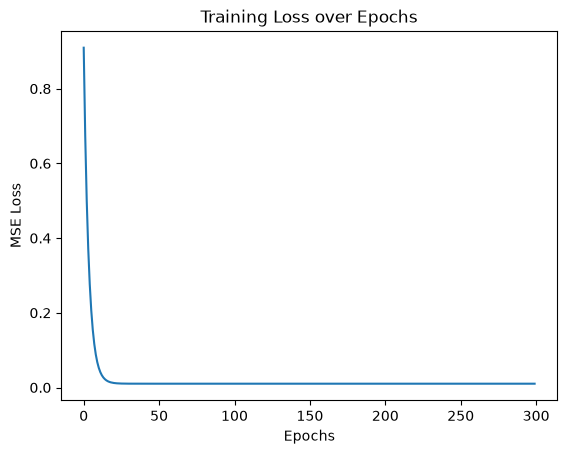

In [165]:
plt.plot(loss_history)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training Loss over Epochs')
plt.show()

In [166]:
### Neural Network with activation function
## Initialize weights and biases
w_11 = np.random.randn()
w_12 = np.random.randn()
w_13 = np.random.randn()
w_14 = np.random.randn()
w_21 = np.random.randn()
w_22 = np.random.randn()
b_11 = np.random.randn()
b_12 = np.random.randn()
b_2 = np.random.randn()

# Training settings
lr = 0.01
epochs = 300

for epoch in range(epochs):
    loss = 0.0
    dL_dw21 = dL_dw22 = 0.0
    dL_dw11 = dL_dw12 = dL_dw13 = dL_dw14 = 0.0
    dL_db11 = dL_db12 = dL_db2 = 0.0
    m = len(X)

    for i in range(m):
        x1 = X[i, 0]
        x2 = X[i, 1]
        target = y[i, 0]

        # --- Forward pass ---
        a1 = w_11 * x1 + w_13 * x2 + b_11
        a2 = w_12 * x1 + w_14 * x2 + b_12

        # ReLU activation
        h1 = np.maximum(0, a1)
        h2 = np.maximum(0, a2)

        # Output layer (no activation, linear regression)
        y_pred = h1 * w_21 + h2 * w_22 + b_2

        # Compute loss
        loss += (y_pred - target) ** 2

        # --- Backward pass ---
        dL_dy = 2 * (y_pred - target)

        # Gradients for output layer
        dL_dw21 += dL_dy * h1
        dL_dw22 += dL_dy * h2
        dL_db2 += dL_dy

        # Gradient wrt hidden activations
        dL_dh1 = dL_dy * w_21
        dL_dh2 = dL_dy * w_22

        # Derivative of ReLU
        relu_prime_a1 = 1.0 if a1 > 0 else 0.0
        relu_prime_a2 = 1.0 if a2 > 0 else 0.0

        # Backprop through ReLU
        dL_da1 = dL_dh1 * relu_prime_a1
        dL_da2 = dL_dh2 * relu_prime_a2

        # Gradients for input-hidden weights
        dL_dw11 += dL_da1 * x1
        dL_dw13 += dL_da1 * x2
        dL_db11 += dL_da1

        dL_dw12 += dL_da2 * x1
        dL_dw14 += dL_da2 * x2
        dL_db12 += dL_da2

    # Average gradients
    dL_dw21 /= m; dL_dw22 /= m
    dL_dw11 /= m; dL_dw13 /= m; dL_dw12 /= m; dL_dw14 /= m
    dL_db2 /= m; dL_db11 /= m; dL_db12 /= m

    # Update weights
    w_21 -= lr * dL_dw21
    w_22 -= lr * dL_dw22
    b_2 -= lr * dL_db2
    w_11 -= lr * dL_dw11
    w_13 -= lr * dL_dw13
    b_11 -= lr * dL_db11
    w_12 -= lr * dL_dw12
    w_14 -= lr * dL_dw14
    b_12 -= lr * dL_db12

    loss /= m
    if epoch % 10 == 0:
        print(f"Epoch {epoch:4d} | Loss: {loss:.6f}")

print("\nFinal Loss:", loss)


Epoch    0 | Loss: 4.393105
Epoch   10 | Loss: 3.234444
Epoch   20 | Loss: 2.579363
Epoch   30 | Loss: 2.122418
Epoch   40 | Loss: 1.775400
Epoch   50 | Loss: 1.503193
Epoch   60 | Loss: 1.276383
Epoch   70 | Loss: 1.081817
Epoch   80 | Loss: 0.924793
Epoch   90 | Loss: 0.799416
Epoch  100 | Loss: 0.700251
Epoch  110 | Loss: 0.620981
Epoch  120 | Loss: 0.556871
Epoch  130 | Loss: 0.504835
Epoch  140 | Loss: 0.462418
Epoch  150 | Loss: 0.427778
Epoch  160 | Loss: 0.399214
Epoch  170 | Loss: 0.375194
Epoch  180 | Loss: 0.354885
Epoch  190 | Loss: 0.337452
Epoch  200 | Loss: 0.322788
Epoch  210 | Loss: 0.310407
Epoch  220 | Loss: 0.299796
Epoch  230 | Loss: 0.290021
Epoch  240 | Loss: 0.281206
Epoch  250 | Loss: 0.273408
Epoch  260 | Loss: 0.266576
Epoch  270 | Loss: 0.260035
Epoch  280 | Loss: 0.252699
Epoch  290 | Loss: 0.244696

Final Loss: 0.23733835991925406


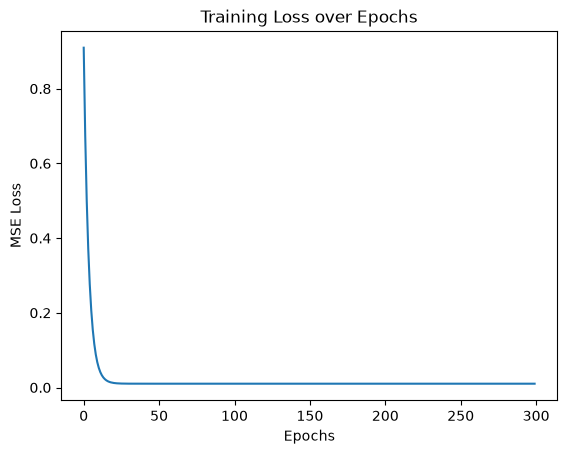

In [167]:
plt.plot(loss_history)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training Loss over Epochs')
plt.show()

### **Vectorized version**

In [168]:
# Initialize weights
np.random.seed(42)
W1 = np.random.randn(2, 2)
b1 = np.zeros((1, 2))
W2 = np.random.randn(2, 1)
b2 = np.zeros((1, 1))

In [169]:
W1

array([[ 0.49671415, -0.1382643 ],
       [ 0.64768854,  1.52302986]])

In [170]:
W2

array([[-0.23415337],
       [-0.23413696]])

In [171]:
b1

array([[0., 0.]])

In [172]:
# Hyperparameters
lr = 0.01
epochs = 500
m = X.shape[0]  # number of samples
loss_list = []

for epoch in range(epochs):
    # ---------- Forward Pass ----------
    # Hidden layer (no activation)
    Z1 = np.dot(X, W1) + b1  # shape (m, 2)
    
    # Output layer (no activation)
    y_pred = np.dot(Z1, W2) + b2  # shape (m, 1)
    
    # ---------- Compute Loss ----------
    loss = np.mean((y_pred - y) ** 2)  # MSE
    loss_list.append(loss)
    
    # ---------- Backpropagation ----------
    # dL/dy_pred
    dL_dy = 2 * (y_pred - y) / m  # shape (m, 1)
    
    # Gradients for W2 and b2
    dL_dW2 = np.dot(Z1.T, dL_dy)         # shape (2, 1)
    dL_db2 = np.sum(dL_dy, axis=0, keepdims=True)  # shape (1, 1)
    
    # Backprop to hidden layer
    dL_dZ1 = np.dot(dL_dy, W2.T)  # shape (m, 2)
    
    # Gradients for W1 and b1
    dL_dW1 = np.dot(X.T, dL_dZ1)  # shape (2, 2)
    dL_db1 = np.sum(dL_dZ1, axis=0, keepdims=True)  # shape (1, 2)
    
    # ---------- Parameter Update ----------
    W2 -= lr * dL_dW2
    b2 -= lr * dL_db2
    W1 -= lr * dL_dW1
    b1 -= lr * dL_db1
    
    # ---------- Print Loss ----------
    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")

Epoch 1/500, Loss: 2.1162
Epoch 100/500, Loss: 0.0809
Epoch 200/500, Loss: 0.0116
Epoch 300/500, Loss: 0.0102
Epoch 400/500, Loss: 0.0102
Epoch 500/500, Loss: 0.0102


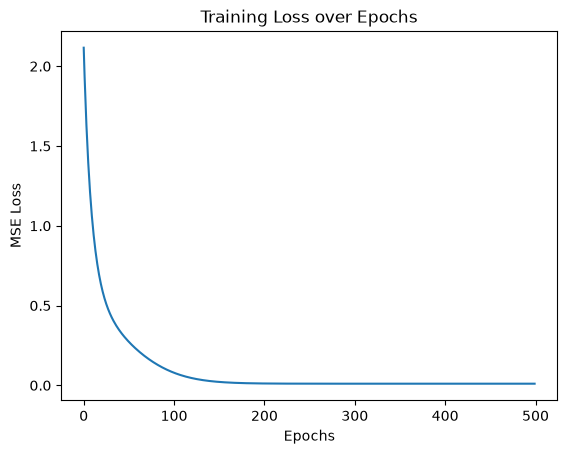

In [173]:
import matplotlib.pyplot as plt

plt.plot(loss_list)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training Loss over Epochs')
plt.show()

# **Building NN with Pytorch**

In [174]:
from sklearn.datasets import make_regression
import numpy as np
import matplotlib.pyplot as plt

# Generate dataset with 2 features
X, y = make_regression(n_samples=1000, n_features=2, noise=10, random_state=42)

# Reshape y to be a column vector
y = y.reshape(-1, 1)
print(X[:5])
# Normalize inputs (optional for stability)
X = (X - X.mean(axis=0)) / X.std(axis=0)
y = (y - y.mean()) / y.std()

print(X.shape, y.shape)  # Should print (1000, 2) (1000, 1)

[[-0.16711808  0.14671369]
 [-0.02090159  0.11732738]
 [ 0.15041891  0.364961  ]
 [ 0.55560447  0.08958068]
 [ 0.05820872 -1.1429703 ]]
(1000, 2) (1000, 1)


In [175]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_val.shape, y_train.shape, y_val.shape)

(800, 2) (200, 2) (800, 1) (200, 1)


In [185]:
### Building the NN using Pytorch
import torch
import torch.nn as nn
import torch.optim as optim

# Define the neural network model
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.hidden_1 = nn.Linear(2, 2) # 2 input features to 2 hidden neurons
        self.output = nn.Linear(2, 1)   # 2 hidden neurons to 1 output

    def forward(self, x):
        x = self.hidden_1(x)
        x = self.output(x)
        return x

In [186]:
model = SimpleNN()
print(model)

SimpleNN(
  (hidden_1): Linear(in_features=2, out_features=2, bias=True)
  (output): Linear(in_features=2, out_features=1, bias=True)
)


In [187]:
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():  # For Apple Silicon
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

Using device: mps


In [188]:
type(X_train)

numpy.ndarray

In [189]:
### Training the model
# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)
model.to(device)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Training loop
epochs = 300
loss_history = []
val_loss_history = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward pass and optimization
    loss.backward()
    optimizer.step()
    
    loss_history.append(loss.item())
    
    # Validation
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_tensor)
        val_loss = criterion(val_outputs, y_val_tensor)
        val_loss_history.append(val_loss.item())
    
    if (epoch + 1) % 50 == 0 or epoch == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}')

Epoch [1/300], Loss: 1.2088, Val Loss: 1.1570
Epoch [50/300], Loss: 0.7210, Val Loss: 0.6940
Epoch [100/300], Loss: 0.3377, Val Loss: 0.3299
Epoch [150/300], Loss: 0.1272, Val Loss: 0.1313
Epoch [200/300], Loss: 0.0712, Val Loss: 0.0777
Epoch [250/300], Loss: 0.0592, Val Loss: 0.0652
Epoch [300/300], Loss: 0.0567, Val Loss: 0.0620


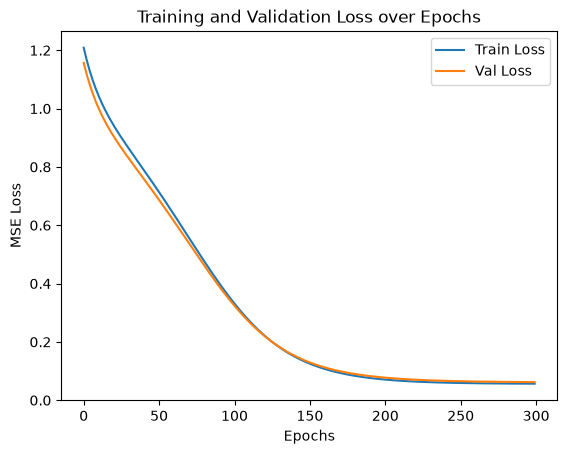

In [190]:
plt.plot(loss_history, label='Train Loss')
plt.plot(val_loss_history, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training and Validation Loss over Epochs')
plt.legend()
plt.show()

# **Classification Problem**

In [191]:
from sklearn.datasets import make_classification
import numpy as np

# Generate 2-feature binary classification dataset
X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

# Reshape y to (m, 1)
y = y.reshape(-1, 1)

print(X.shape, y.shape)  # Should print (500, 2) (500, 1)

(500, 2) (500, 1)


In [192]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, y_train.shape)  # Should print (400, 2) (400, 1)
print(X_test.shape, y_test.shape)    # Should print (100, 2)

(400, 2) (400, 1)
(100, 2) (100, 1)


In [193]:
### Neural Network for Classification (2->2->1)
## Initialize weights
np.random.seed(42)
W1 = np.random.randn(2, 2) * 0.1
b1 = np.zeros((1, 2))
W2 = np.random.randn(2, 1) * 0.1
b2 = np.zeros((1, 1))

epochs = 500
lr = 0.01
m = X_train.shape[0]
loss_list = []

for epoch in range(epochs):
    # ---------- Forward Pass ----------
    # Hidden layer
    Z1 = np.dot(X_train, W1) + b1  # shape (m, 2)
    # Activation (ReLU)
    A1 = np.maximum(0, Z1)          # shape (m, 2)
    # Output layer
    Z2 = np.dot(A1, W2) + b2        # shape (m, 1)
    # Activation (Sigmoid)
    y_pred = 1 / (1 + np.exp(-Z2))  # shape (m, 1)
    # ---------- Compute Loss (Binary Cross-Entropy) ----------
    loss = -np.mean(y_train * np.log(y_pred + 1e-8) + (1 - y_train) * np.log(1 - y_pred + 1e-8))
    loss_list.append(loss)
    # ---------- Backpropagation ----------
    dL_dy = -(y_train / (y_pred + 1e-8)) + ((1 - y_train) / (1 - y_pred + 1e-8))  # shape (m, 1)
    dL_dZ2 = dL_dy * y_pred * (1 - y_pred)  # shape (m, 1)
    dL_dW2 = np.dot(A1.T, dL_dZ2)           # shape (2, 1)
    dL_db2 = np.sum(dL_dZ2, axis=0, keepdims=True)  # shape (1, 1)
    dL_dA1 = np.dot(dL_dZ2, W2.T)  # shape (m, 2)
    dL_dZ1 = dL_dA1 * (Z1 > 0)  # ReLU backprop
    dL_dW1 = np.dot(X_train.T, dL_dZ1)  # shape (2, 2)
    dL_db1 = np.sum(dL_dZ1, axis=0, keepdims=True)  # shape (1, 2)
    # ---------- Parameter Update ----------
    W2 -= lr * dL_dW2
    b2 -= lr * dL_db2
    W1 -= lr * dL_dW1
    b1 -= lr * dL_db1
    # ---------- Print Loss ----------
    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")
    



Epoch 1/500, Loss: 0.6935
Epoch 100/500, Loss: 0.2190
Epoch 200/500, Loss: 0.2094
Epoch 300/500, Loss: 0.2100
Epoch 400/500, Loss: 0.2097
Epoch 500/500, Loss: 0.2096


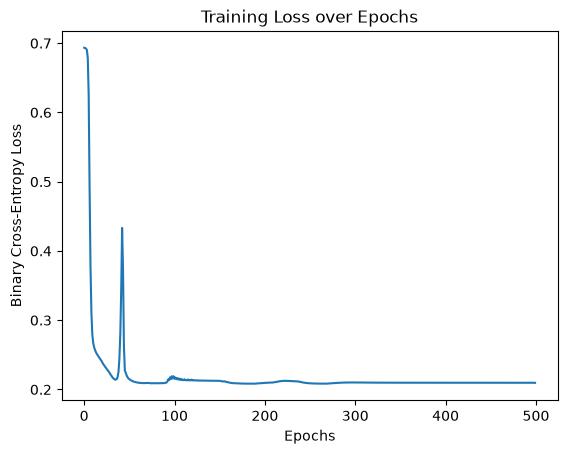

In [194]:
plt.plot(loss_list)
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Training Loss over Epochs')
plt.show()

In [195]:
### predict on test set
# Forward pass on test set
Z1_test = np.dot(X_test, W1) + b1
A1_test = np.maximum(0, Z1_test)
Z2_test = np.dot(A1_test, W2) + b2
y_pred_test = 1 / (1 + np.exp(-Z2_test))
# Convert probabilities to class labels
y_pred_labels = (y_pred_test >= 0.5).astype(int)
# Calculate accuracy
accuracy = np.mean(y_pred_labels == y_test)
print(f"Test Set Accuracy: {accuracy * 100:.2f}%")

Test Set Accuracy: 91.00%


In [196]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_labels))
print(confusion_matrix(y_test, y_pred_labels))

              precision    recall  f1-score   support

           0       0.94      0.88      0.91        50
           1       0.89      0.94      0.91        50

    accuracy                           0.91       100
   macro avg       0.91      0.91      0.91       100
weighted avg       0.91      0.91      0.91       100

[[44  6]
 [ 3 47]]


# **Building NN with Pytorch (Classification)**

In [197]:
from sklearn.datasets import make_classification
import numpy as np

# Generate 2-feature binary classification dataset
X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

# Reshape y to (m, 1)
y = y.reshape(-1, 1)

print(X.shape, y.shape)  # Should print (500, 2) (500, 1)

(500, 2) (500, 1)


In [198]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, y_train.shape)  # Should print (400, 2) (400, 1)
print(X_test.shape, y_test.shape)    # Should print (100, 2)

(400, 2) (400, 1)
(100, 2) (100, 1)


In [199]:
### Building the NN using Pytorch
import torch
import torch.nn as nn
import torch.optim as optim

# Define the neural network model
class SimpleNNClassifier(nn.Module):
    def __init__(self):
        super(SimpleNNClassifier, self).__init__()
        self.hidden = nn.Linear(2, 10)  # 2 input features to 2 hidden neurons
        self.hidden_2  = nn.Linear(10, 5)
        self.act_fun = nn.ReLU()
        # self.act_fun = nn.Tanh()
        self.act_fun_2 = nn.LeakyReLU()
        # self.act_fun = nn.ELU()
        # self.act_fun = nn.SELU()
        # self.act_fun = nn.SiLU()
        # self.act_fun = nn.Sigmoid()
        self.output = nn.Linear(5, 1)   # 2 hidden neurons to 1 output
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.hidden(x)
        x = self.act_fun(x)
        x = self.hidden_2(x)
        x = self.act_fun_2(x)
        x = self.output(x)
        x = self.sigmoid(x)
        return x

In [200]:
model = SimpleNNClassifier()
print(model)

SimpleNNClassifier(
  (hidden): Linear(in_features=2, out_features=10, bias=True)
  (hidden_2): Linear(in_features=10, out_features=5, bias=True)
  (act_fun): ReLU()
  (act_fun_2): LeakyReLU(negative_slope=0.01)
  (output): Linear(in_features=5, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [201]:
### Trainig the model
# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).to(device)
model.to(device)

# Loss function and optimizer
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

# Training loop
epochs = 1000
loss_history = []
val_loss_history = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward pass and optimization
    loss.backward()
    optimizer.step()
    
    loss_history.append(loss.item())
    
    # Validation
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_test_tensor)
        val_loss = criterion(val_outputs, y_test_tensor)
        val_loss_history.append(val_loss.item())
    
    if (epoch + 1) % 50 == 0 or epoch == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}')

Epoch [1/1000], Loss: 0.6733, Val Loss: 0.6775
Epoch [50/1000], Loss: 0.4025, Val Loss: 0.4085
Epoch [100/1000], Loss: 0.2773, Val Loss: 0.2952
Epoch [150/1000], Loss: 0.2481, Val Loss: 0.2688
Epoch [200/1000], Loss: 0.2346, Val Loss: 0.2575
Epoch [250/1000], Loss: 0.2244, Val Loss: 0.2496
Epoch [300/1000], Loss: 0.2169, Val Loss: 0.2453
Epoch [350/1000], Loss: 0.2102, Val Loss: 0.2416
Epoch [400/1000], Loss: 0.2042, Val Loss: 0.2384
Epoch [450/1000], Loss: 0.1983, Val Loss: 0.2351
Epoch [500/1000], Loss: 0.1926, Val Loss: 0.2316
Epoch [550/1000], Loss: 0.1874, Val Loss: 0.2279
Epoch [600/1000], Loss: 0.1826, Val Loss: 0.2242
Epoch [650/1000], Loss: 0.1780, Val Loss: 0.2200
Epoch [700/1000], Loss: 0.1738, Val Loss: 0.2156
Epoch [750/1000], Loss: 0.1697, Val Loss: 0.2111
Epoch [800/1000], Loss: 0.1653, Val Loss: 0.2057
Epoch [850/1000], Loss: 0.1613, Val Loss: 0.2026
Epoch [900/1000], Loss: 0.1573, Val Loss: 0.1999
Epoch [950/1000], Loss: 0.1537, Val Loss: 0.1974
Epoch [1000/1000], Loss

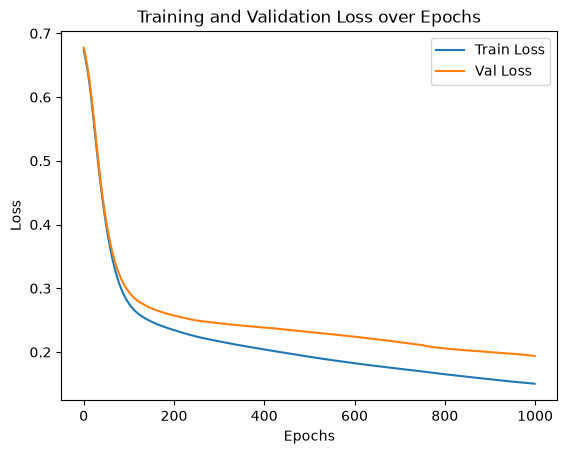

In [202]:
plt.plot(loss_history, label='Train Loss')
plt.plot(val_loss_history, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss over Epochs')
plt.legend()
plt.show()

In [203]:
### Test set evaluation
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    predicted = (test_outputs.cpu().numpy() >= 0.5).astype(int)
    accuracy = np.mean(predicted == y_test)
    print(f'Test Set Accuracy: {accuracy * 100:.2f}%')

Test Set Accuracy: 91.00%


In [204]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, predicted))
print(confusion_matrix(y_test, predicted))

              precision    recall  f1-score   support

           0       0.94      0.88      0.91        50
           1       0.89      0.94      0.91        50

    accuracy                           0.91       100
   macro avg       0.91      0.91      0.91       100
weighted avg       0.91      0.91      0.91       100

[[44  6]
 [ 3 47]]


### **Deep Neural Network**

In [ ]:
from sklearn.datasets import make_classification
import numpy as np

# Generate 2-feature binary classification dataset
X, y = make_classification(
    n_samples=10000,
    n_features=100,
    n_informative=2,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

# Reshape y to (m, 1)
y = y.reshape(-1, 1)

print(X.shape, y.shape)  # Should print (500, 2) (500, 1)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, y_train.shape)  
print(X_test.shape, y_test.shape)    

In [205]:
### Building the NN using Pytorch
import torch
import torch.nn as nn
import torch.optim as optim

# Define the neural network model
class DNNClassifier(nn.Module):
    def __init__(self):
        super(DNNClassifier, self).__init__()
        self.hidden_1 = nn.Linear(100, 10)
        self.act_f_1 = nn.ReLU()
        self.hidden_2 = nn.Linear(10, 20)
        self.act_f_2 = nn.Tanh()
        self.hidden_3 = nn.Linear(20, 10)
        self.act_f_3 = nn.SELU()
        self.out = nn.Linear(10, 1)
        self.act_out = nn.Sigmoid()

    def forward(self, x):
        x = self.hidden_1(x)
        x = self.act_f_1(x)
        x = self.hidden_2(x)
        x = self.act_f_2(x)
        x = self.hidden_3(x)
        x = self.act_f_3(x)
        x = self.out(x)
        x = self.act_out(x)
        return x

In [206]:
model = DNNClassifier()
print(model)

DNNClassifier(
  (hidden_1): Linear(in_features=100, out_features=10, bias=True)
  (act_f_1): ReLU()
  (hidden_2): Linear(in_features=10, out_features=20, bias=True)
  (act_f_2): Tanh()
  (hidden_3): Linear(in_features=20, out_features=10, bias=True)
  (act_f_3): SELU()
  (out): Linear(in_features=10, out_features=1, bias=True)
  (act_out): Sigmoid()
)


In [207]:
### Trainig the model
# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).to(device)
model.to(device)

# Loss function and optimizer
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Training loop
epochs = 1000
loss_history = []
val_loss_history = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    
    # Backward pass and optimization
    loss.backward()
    optimizer.step()
    
    loss_history.append(loss.item())
    
    # Validation
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_test_tensor)
        val_loss = criterion(val_outputs, y_test_tensor)
        val_loss_history.append(val_loss.item())
    
    if (epoch + 1) % 50 == 0 or epoch == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}')

RuntimeError: linear(): input and weight.T shapes cannot be multiplied (400x2 and 100x10)

In [ ]:
plt.plot(loss_history, label='Train Loss')
plt.plot(val_loss_history, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss over Epochs')
plt.legend()
plt.show()

In [ ]:
### Test set evaluation
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    predicted = (test_outputs.cpu().numpy() >= 0.5).astype(int)
    accuracy = np.mean(predicted == y_test)
    print(f'Test Set Accuracy: {accuracy * 100:.2f}%')

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, predicted))
print(confusion_matrix(y_test, predicted))

In [ ]:
import pandas as pd
import numpy as np
data = pd.read_csv("Bin_packing.csv")
data.head()

In [ ]:
data.info()

In [ ]:
# X = first 11 columns
X = data.iloc[:, :11]

# y = remaining columns
y = data.iloc[:, 11:]

print(X.shape)
print(y.shape)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ==========================
# 1. Load Data
# ==========================
data = pd.read_csv("Bin_packing.csv")

X = data.iloc[:, :11].values.astype(np.float32)
y = data.iloc[:, 11:].values.astype(np.float32)

# ==========================
# 2. Train/Test Split (90/10)
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42
)

# ==========================
# 3. Normalize Inputs
# ==========================
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

# Normalize outputs too (optional but recommended)
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled  = scaler_y.transform(y_test)

# ==========================
# 4. PyTorch Dataset
# ==========================
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = MyDataset(X_train_scaled, y_train_scaled)
test_ds  = MyDataset(X_test_scaled,  y_test_scaled)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_ds, batch_size=32)

# ==========================
# 5. Simple Neural Network
# ==========================
class SimpleNN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(SimpleNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.model(x)

In [ ]:
model = SimpleNN(input_dim=11, output_dim=y.shape[1])
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# ==========================
# 6. Training Loop
# ==========================
epochs = 50
losses = []
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for Xb, yb in train_loader:
        optimizer.zero_grad()
        preds = model(Xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        losses.append(loss.item())

    print(f"Epoch {epoch+1}/{epochs}  Train Loss: {total_loss/len(train_loader):.4f}")


In [ ]:
# ==========================
# 7. Evaluation + Recover Original Values
# ==========================
model.eval()
predictions = []
actuals = []

with torch.no_grad():
    for Xb, yb in test_loader:
        preds = model(Xb)
        predictions.append(preds.numpy())
        actuals.append(yb.numpy())

predictions = np.vstack(predictions)
actuals = np.vstack(actuals)

# Recover original scale (inverse transform)
predictions_original = scaler_y.inverse_transform(predictions)
actuals_original = scaler_y.inverse_transform(actuals)

# ==========================
# 8. Evaluation Metrics
# ==========================
mse = np.mean((predictions_original - actuals_original)**2)
mae = np.mean(np.abs(predictions_original - actuals_original))

print("MSE:", mse)
print("MAE:", mae)


In [ ]:
# Print first 5 comparisons
print("\nFirst 5 Actual vs Predicted:")
for i in range(5):
    print("Actual:    ", actuals_original[i])
    print("Predicted: ", predictions_original[i])
    print("---")

In [ ]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.xlabel('Iterations')
plt.ylabel('MSE Loss')
plt.title('Training Loss over Iterations')
plt.show()